In [1]:
import pymupdf
from PIL import Image

In [2]:
doc = pymupdf.open("sample_data/student_sheet_1.pdf")

In [3]:
images = []

for page in doc:
    pix = page.get_pixmap(dpi=300)
    img = Image.frombytes("RGB", [pix.width, pix.height], pix.samples)
    images.append(img)

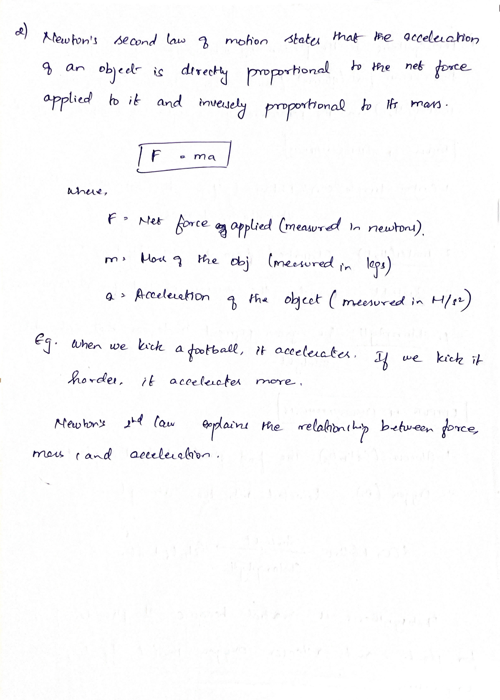

In [4]:
images[1].resize((500,700))

In [7]:
import dotenv
import os
from google import genai
from google.genai import types

dotenv.load_dotenv(override=True)

api_key = os.getenv("GEMINI_API_KEY") or os.getenv("GOOGLE_API_KEY")
model_name = os.getenv("MODEL", "gemini-3.8-flash")

# Configure HTTP options with a 30,000 ms (30 second) timeout
client = genai.Client(
    api_key=api_key
)

In [16]:
for idx, img in enumerate(images):
    max_dim = 768
    if max(img.size) > max_dim:
        img.thumbnail((max_dim, max_dim), Image.Resampling.LANCZOS)

    prompt = (
        "Perform verbatim OCR on this handwritten student answer sheet.\n"
        "Rules:\n"
        "1. Output plain text and standard Markdown only.\n"
        "2. Do NOT use LaTeX tags like \\text{}, \\boxed{}, \\underline{}, or \\mathrm{}.\n"
        "3. Keep chemical/math formulas clean and simple (e.g., CO2, H2O, or standard superscripts/subscripts).\n"
        "4. Transcribe exactly what is written, including question numbers."
        # "5. Ignore any scratched-out, erased, or crossed-out words completely. Do NOT use strikethrough notation like ~~word~~."
    )

    try:
        response = client.models.generate_content(
            model=model_name,
            contents=[img, prompt],
            config=types.GenerateContentConfig(
                temperature=0.0,
                # http_options={"timeout": 45000}
            )
        )
        print(f"\n--- Page {idx+1} Vision Output ---")
        print(response.text)
    except Exception as err:
        print(f"\n--- Page {idx+1} timed out or failed after 30 seconds ---")
        print(f"Error details: {err}")


--- Page 1 timed out or failed after 30 seconds ---
Error details: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}


KeyboardInterrupt: 